# MSH 3-T-junction array: tensor-network LDOS, Z/X gates, fusion readout and δn(x, t)

Combines `ldos_charge_density_tn.ipynb` and `msh_tjunction_gates.ipynb`. The kwant counterparts are
`3_tjunctions_kwant.ipynb` (gates) and `ldos_charge_density_kwant.ipynb` (LDOS, δn), which read the CSVs written here.

**Model.** Chain sites only: horizontal chain $y = 0$, $x = -48\dots47$, T-junctions at $x_c = -32, 0, 32$, vertical legs
$y = 1\dots16$ (144 sites). Nambu basis $(c_\uparrow, c_\downarrow, c^\dagger_\uparrow, c^\dagger_\downarrow)$,
$H_{\rm BdG} = [[H_0, \Delta i\sigma_y], [(\Delta i\sigma_y)^\dagger, -H_0^*]]$, $H_0 = -\mu + J\,\mathbf S\cdot\boldsymbol\sigma$ on sites and
$c^\dagger_{r+\hat d}\,(-t + i\alpha(d_x\sigma_y - d_y\sigma_x))\,c_r$ on bonds; $t=1$, $\mu=-7$, $\alpha=0.9$, $\Delta=2.4$, $J=5.8$.
Texture $\theta = (-1)^{x+y}\tfrac{\pi}{2}f$, $\phi = \theta_{\rm arm} + \pi/2$: $f = 0$ topological ($\mathbf S\parallel\hat z$), $f = 1$ trivial
(in-plane AFM). Initial setup: junctions 1 and 3 have topological horizontal legs, the rest is trivial → four MZMs.

**Tensor-network parts.**
* $H$ is an MPO (TensorBinding.jl) on `[nambu; spin; cell; pos₁…pos₄; arm]`, checked against an independent dense lattice matrix.
* LDOS and MZMs: penalized DMRG on $K = H^2 + \eta^2$, Rayleigh–Ritz in $H$, inverse-iteration refinement, localization with the position MPO.
* Time evolution: the two zero-mode fermions are evolved exactly (midpoint Taylor steps, $dt = 0.1$) with the dense form of the
  same $H(t)$ (equal to the MPO to ~1e-10). The **full MPS/TDVP evolution** (`msh_gate_density_tdvp.jl`, 1–2 h per mode) is loaded
  from `msh_gate_density_tdvp_{Z,X}.csv` and compared (Section 7). `RUN_TDVP = true` reruns a short TDVP window in the notebook.

**Outputs:** `msh_array_ldos_tn.csv`, `msh_gate_density_tn_{Z,X}.csv`, `tb_reference/`, figures `nb_tn_ldos.png`,
`nb_tn_density_{Z,X}.png`, `nb_tdvp_density_{Z,X}.png`. Runtime ≈ 15 min single-threaded (MPS ~4 min, gates ~10 min).

| Quantity | Julia / TensorBinding | kwant V6 |
|---|---|---|
| MZM positions $x$ | −46.6, −17.5, 16.5, 45.6 | −46.6, −17.5, 16.5, 45.6 |
| first state above the MZMs (junction-2 bound state) | 0.127 | 0.127 |
| exchange_12 once: relative phase | 90.718° | 90.718° |
| Z = exchange_12 × 2: relative phase / leak | 181.44° / 2e-6 | 181.436° / 2e-6 |
| fusion ΔQ after Z / no gate / adiabatic | −0.4777 / −0.4774 / −0.4769 | −0.4777 / −0.4774 / −0.4769 |
| X (rot_Tx = 100): leak (A, B) / ΔQ | 0.108, 0.093 / +0.444 | 0.108, 0.093 / +0.444 |
| X (rot_Tx = 400): θ / P(0→1) / leak / ΔQ | 174.94° / 0.99805 / 3.4e-5 / +0.4770 | 174.94° / 0.99805 / 3.4e-5 / +0.4770 |

In [1]:
using LinearAlgebra, Printf, Random, DelimitedFiles, Logging
using ITensors, ITensorMPS, Plots
using TensorBinding
const TB = TensorBinding

const ROOT = pwd()          # CSVs and figures are read from / written to the notebook's folder
const RUN_TDVP = false      # short in-notebook TDVP check (~20 min); the full TDVP run is loaded from CSV in Section 7
const σ0 = ComplexF64[1 0; 0 1];  const σx = ComplexF64[0 1; 1 0]
const σy = ComplexF64[0 -im; im 0]; const σz = ComplexF64[1 0; 0 -1]
# KrylovKit warns at every non-converged local solve in DMRG on K and in linsolve (harmless); show errors only
quiet(f) = with_logger(f, ConsoleLogger(stderr, Logging.Error))

quiet (generic function with 1 method)

## 1. Hamiltonian: MPO and dense reference

* `diag_mpo_exact`: exact diagonal MPO (TT-SVD) for the site-dependent exchange field.
* `msh_tjunction_array(a, f)`: BdG MPO. Intra-arm hopping with `shift_pair_mpos(cyclic=false)`, junction bonds via the site-0
  projector, inter-cell bonds via the site-$(N-1)$ projector. Each cell is a lattice T: arm 1 runs right from the junction site,
  arm 2 left from $x_c - 1$, arm 3 up from $y = 1$.
* `array_reference(a, f)`: independent dense matrix built only from site coordinates (all pairs one lattice spacing apart).
* `array_exchange_mpo` / `add_exchange_dense!`: exchange of selected cells only, so $H(t)$ = fixed part + moving exchange.

`f(c, s, n)` is the rotation fraction on cell `c`, arm `s` (1 right, 2 left, 3 up), site `n` along the arm.

In [2]:
# exact diagonal MPO diag(v) on the position qubits (pos[1] = most significant bit)
function diag_mpo_exact(v::AbstractVector, pos; cutoff=1e-14)
    L = length(pos)
    A = permutedims(reshape(ComplexF64.(v), ntuple(_ -> 2, L)), L:-1:1)
    ψ = MPS(A, pos; cutoff=cutoff)
    W = MPO(pos, "Id")
    for k in 1:L
        s = pos[k]
        δ = ITensor(ComplexF64, s, s', dag(s''))
        for j in 1:2; δ[s => j, s' => j, s'' => j] = 1; end
        W[k] = replaceprime(ψ[k] * δ, 2 => 0; tags=tags(s))
    end
    return W
end

# dense matrix of an MPO / vector of an MPS (big-endian over `sites`), and back
dense(mpo, sites) = (T = ITensors.@disable_warn_order prod(mpo); D = prod(dim.(sites));
                     reshape(Array(T, reverse(prime.(sites))..., reverse(sites)...), D, D))
dense_vec(ψ, sites) = vec(Array(ITensors.@disable_warn_order(prod(ψ)), reverse(sites)...))
mps_from_dense(v, sites; cutoff=1e-16) = MPS(ITensor(reshape(ComplexF64.(v), dim.(reverse(sites))...), reverse(sites)...),
                                             sites; cutoff)

# hopping c†_{r+d} h c_r along the unit bond d
hop_matrix(t, α, d) = -t * σ0 + im * α * (d[1] * σy - d[2] * σx)

Base.@kwdef struct TArray
    L::Int = 4          # 2^L = 16 sites per arm
    ncell::Int = 3
end
Ncell(a::TArray) = 2^a.L
const ARM_ANG = (0.0, π, π/2)                         # right, left, up
const ARM_ORIG = ((0.0, 0.0), (-1.0, 0.0), (0.0, 1.0))
center_x(a::TArray, c) = (c - (a.ncell + 1) / 2) * 2Ncell(a)
array_pos(a::TArray, c, s, n) = (center_x(a, c), 0.0) .+ ARM_ORIG[s] .+ n .* (cos(ARM_ANG[s]), sin(ARM_ANG[s]))
array_spin(a::TArray, f) = (c, s, n) -> begin
    x, y = round.(Int, array_pos(a, c, s, n))
    θ = (-1)^(x + y) * (π/2) * f(c, s, n); φ = ARM_ANG[s] + π/2
    (cos(φ) * sin(θ), sin(φ) * sin(θ), cos(θ))
end

function msh_tjunction_array(a::TArray, f; t=1.0, μ=-7.0, α=0.9, Δ=2.4, J=5.8, cutoff=1e-13)
    L, N, nc = a.L, Ncell(a), a.ncell
    ns, ss, cl = TB.nambu_index(), TB.spin_index(), Index(nc, "Cell")
    pos, arm = siteinds("Qubit", L), TB.tjunction_index()
    term(Mpos, σmat, Bcell, Barm) =
        TB.prepend_op(TB.prepend_op(TB.postpend_op(Mpos, arm, Barm), cl, Bcell), ss, σmat)
    P(d, i) = (m = zeros(d, d); m[i, i] = 1.0; m)
    E(d, i, j) = (m = zeros(d, d); m[i, j] = 1.0; m)         # |i⟩⟨j|
    Ic, I3, Id = Matrix(1.0I, nc, nc), Matrix(1.0I, 3, 3), MPO(pos, "Id")
    Ku, Kd = TB.shift_pair_mpos(pos, 1; cyclic=false)

    terms = MPO[term(-μ * Id, σ0, Ic, I3)]
    for s in 1:3                                              # intra-arm hopping
        h = hop_matrix(t, α, (cos(ARM_ANG[s]), sin(ARM_ANG[s])))
        push!(terms, term(Ku, h, Ic, P(3, s)), term(Kd, Matrix(h'), Ic, P(3, s)))
    end
    P0 = TB._site_projector_mpo(L, pos, 0)                     # junction bonds
    for (a_, b_, d) in ((2, 1, (1.0, 0.0)), (1, 2, (-1.0, 0.0)), (3, 1, (0.0, -1.0)), (1, 3, (0.0, 1.0)))
        push!(terms, term(P0, hop_matrix(t, α, d), Ic, E(3, b_, a_)))
    end
    Pend = TB._site_projector_mpo(L, pos, N - 1)               # inter-cell: right end of c → left end of c+1
    h = hop_matrix(t, α, (1.0, 0.0))
    for c in 1:nc-1
        push!(terms, term(Pend, h, E(nc, c + 1, c), E(3, 2, 1)),
                     term(Pend, Matrix(h'), E(nc, c, c + 1), E(3, 1, 2)))
    end
    S = array_spin(a, f)                                       # exchange J S·σ
    for c in 1:nc, s in 1:3, (k, σ) in enumerate((σx, σy, σz))
        v = [J * S(c, s, n)[k] for n in 0:N-1]
        maximum(abs, v) > 1e-14 && push!(terms, term(diag_mpo_exact(v, pos), σ, P(nc, c), P(3, s)))
    end
    H0 = +(terms...; cutoff)

    Hp  = term(Δ * Id, ComplexF64[0 1; -1 0], Ic, I3)
    Hpd = swapprime(dag(Hp), 0, 1)
    HB  = +(TB.prepend_nambu(H0, ns, :Pp), TB.prepend_nambu(-1.0 * dag(H0), ns, :Ph),
            TB.prepend_nambu(Hp, ns, :tp), TB.prepend_nambu(Hpd, ns, :tm); cutoff)
    return HB, [ns; ss; cl; pos; arm]
end

"Independent dense BdG matrix from site coordinates only (same basis as dense(HB, sites))."
function array_reference(a::TArray, f; t=1.0, μ=-7.0, α=0.9, Δ=2.4, J=5.8)
    N, nc = Ncell(a), a.ncell; S = array_spin(a, f); M = 3N * nc
    idx(c, s, n) = (c - 1) * 3N + 3n + s                       # cell ⊗ pos ⊗ arm, arm fastest
    allsites = [(c, s, n, array_pos(a, c, s, n)) for c in 1:nc for s in 1:3 for n in 0:N-1]
    H0 = zeros(ComplexF64, 2M, 2M)
    blk(i) = [i, M + i]
    for (c, s, n, r) in allsites
        i = idx(c, s, n); Sn = S(c, s, n)
        H0[blk(i), blk(i)] .+= -μ * σ0 + J * (Sn[1] * σx + Sn[2] * σy + Sn[3] * σz)
        for (c2, s2, n2, r2) in allsites
            d = r2 .- r
            abs(hypot(d...) - 1) < 1e-9 && (H0[blk(idx(c2, s2, n2)), blk(i)] .+= hop_matrix(t, α, d))
        end
    end
    D = kron(Δ * ComplexF64[0 1; -1 0], Matrix(1.0I, M, M))
    return [H0 D; D' -conj(H0)]
end

"Exchange J S·σ (particle σ, hole −σ*) of the given cells only, as a BdG MPO on `sites`."
function array_exchange_mpo(a::TArray, sites, f, cells; J=5.8, cutoff=1e-14)
    ns, ss, cl, pos, arm = sites[1], sites[2], sites[3], sites[4:end-1], sites[end]
    S = array_spin(a, f); N = Ncell(a); H = nothing
    for c in cells, s in 1:3, (k, σ) in enumerate((σx, σy, σz))
        v = [J * S(c, s, n)[k] for n in 0:N-1]
        maximum(abs, v) > 1e-14 || continue
        Pc = zeros(a.ncell, a.ncell); Pc[c, c] = 1.0
        Pa = zeros(3, 3); Pa[s, s] = 1.0
        D = TB.prepend_op(TB.postpend_op(diag_mpo_exact(v, pos), arm, Pa), cl, Pc)
        m = +(TB.prepend_nambu(TB.prepend_op(D, ss, σ), ns, :Pp),
              TB.prepend_nambu(TB.prepend_op(D, ss, -conj(σ)), ns, :Ph); cutoff)
        H = isnothing(H) ? m : +(H, m; cutoff)
    end
    return H
end

"Exchange blocks of texture f added in place to a dense matrix (ordering of array_reference)."
function add_exchange_dense!(H, a::TArray, f; J=5.8)
    N, nc = Ncell(a), a.ncell; M = 3N * nc; S = array_spin(a, f)
    for c in 1:nc, s in 1:3, n in 0:N-1
        i = (c - 1) * 3N + 3n + s; Sn = S(c, s, n)
        m = J * (Sn[1] * σx + Sn[2] * σy + Sn[3] * σz)
        for α in 1:2, β in 1:2
            H[(α-1)*M + i, (β-1)*M + i] += m[α, β]
            H[2M + (α-1)*M + i, 2M + (β-1)*M + i] -= conj(m[α, β])
        end
    end
    return H
end

"Diagonal position operator r·û (û at angle β) on [nambu; spin; cell; pos; arm]."
function array_position_mpo(a::TArray, sites; β=0.05)
    ns, ss, cl, pos, arm = sites[1], sites[2], sites[3], sites[4:end-1], sites[end]
    u = (cos(β), sin(β)); X = nothing
    for c in 1:a.ncell, s in 1:3
        Pc = zeros(a.ncell, a.ncell); Pc[c, c] = 1.0
        Pa = zeros(3, 3); Pa[s, s] = 1.0
        v = [sum(array_pos(a, c, s, n) .* u) for n in 0:Ncell(a)-1]
        m = TB.prepend_op(TB.postpend_op(diag_mpo_exact(v, pos), arm, Pa), cl, Pc)
        X = isnothing(X) ? m : +(X, m; cutoff=1e-14)
    end
    return TB.prepend_op(TB.prepend_op(X, ss, σ0), ns, σ0)
end

# per-site weight (Nambu and spin summed) of a dense vector → [arm, n, cell]
array_weight(v, a::TArray) = dropdims(sum(abs2, reshape(v, 3, Ncell(a), a.ncell, 2, 2); dims=(4, 5)); dims=(4, 5))
site_list(a) = [(c, s, n) for c in 1:a.ncell for n in 0:Ncell(a)-1 for s in 1:3]      # order of vec(array_weight)

site_list (generic function with 1 method)

## 2. Protocols (CZ_mixed_encoding_V5 ramps mapped onto the array)

`cz_smoothstep(τ) = sin²(πτ/2)` on [0, 1]; each site's $f$ ramps with a site-dependent delay `step_T · d`, τ = t / rot_T.
V5's formulas are kept for $L_1 = L_2 = 14$ and mapped onto the 16-site legs.
* **exchange_12** (cell 1, `rot_Tz = 200`, `step_Tz = 0.1`) exchanges γ₁ and γ₂ around junction 1's vertical leg; Z = exchange_12 × 2.
  Arm 1 $n \leftrightarrow i = L_1 + 1 + n$; arm 2 $n \leftrightarrow i = \max(L_1 - n, 0)$; arm 3 $n \leftrightarrow k = \min(n, L_2)$.
* **exchange_23** (cell 2, `rot_Tx = 100` or 400) exchanges γ₂ and γ₃ through the trivial junction 2; X = exchange_23 × 2.
  Right arm $i = 3L_1 + 3 + n$; the left arm's 16 sites are mapped linearly onto $i = 3L_1 + 2 \dots 2L_1 + 3$.
* **Partial fusion** of pair A (fuse_56 analogue on cell 1, `rot_T0 = 100`, `step_T0 = 0.2`, `Lp = 1`): both halves turn trivial from
  the outer ends inward, leaving $2L_p + 1 = 3$ topological sites around the junction.

In [3]:
cz_smoothstep(τ) = τ <= 0 ? 0.0 : τ >= 1 ? 1.0 : sin(π * τ / 2)^2
const f0 = (c, s, n) -> (c == 2 || s == 3) ? 1.0 : 0.0     # initial setup

Base.@kwdef struct Exchange12
    L1::Int = 14; L2::Int = 14; rot_T::Float64 = 200.0; step_T::Float64 = 0.1
end
duration(p::Exchange12) = (p.step_T * (4p.L1 + 2p.L2 + 8) + 1) * p.rot_T      # V5's t0z cuts off the last rotation
function f_horizontal(p::Exchange12, i, t)
    τ, s, L1, L2 = t / p.rot_T, p.step_T, p.L1, p.L2; ss = cz_smoothstep
    0 <= i <= L1           && return ss(τ - s * (i + L1 + L2 + 2)) - ss(τ - s * (L1 - i + 3L1 + 2L2 + 8))
    i == L1 + 1            && return 0.0
    L1 + 2 <= i <= 2L1 + 2 && return ss(τ - s * (2L1 + 2 - i)) - ss(τ - s * (i + L1 + L2 + 2))
    return 1.0
end
f_vertical(p::Exchange12, k, t) = (τ = t / p.rot_T; s = p.step_T; ss = cz_smoothstep;
                                   1 - ss(τ - s * (k + p.L1 + 2)) + ss(τ - s * (p.L2 - k + 3p.L1 + p.L2 + 5)))
f_braid(p::Exchange12, t) = (s, n) -> s == 1 ? f_horizontal(p, p.L1 + 1 + n, t) :
                                      s == 2 ? f_horizontal(p, max(p.L1 - n, 0), t) :
                                               f_vertical(p, min(n, p.L2), t)
f_array_braid(a::TArray, p::Exchange12, f0, t) = (c, s, n) -> c == 1 ? f_braid(p, t)(s, n) : f0(c, s, n)

Base.@kwdef struct Exchange23
    L1::Int = 14; L2::Int = 14; rot_T::Float64 = 100.0; step_T::Float64 = 0.1
end
duration(p::Exchange23) = (p.step_T * (p.L1 + 3p.L2 + 2p.L1 + 3) + 1) * p.rot_T
function f_h23(p::Exchange23, i, t)
    τ, s, L1, L2 = t / p.rot_T, p.step_T, p.L1, p.L2; ss = cz_smoothstep
    2L1 + 3 <= i <= 3L1 + 3 && return 1 - ss(τ - s * (i - 2L1 - 3)) + ss(τ - s * (4L1 + 4 - i + L2 + L1 + 2))
    3L1 + 4 <= i <= 4L1 + 4 && return 1 - ss(τ - s * (4L1 + 4 - i + L2 + L1 + 1)) + ss(τ - s * (i - 3L1 - 4 + 3L2 + 2L1 + 3))
    error("i = $i outside junction 2's segment")
end
f_v23(p::Exchange23, k, t) = (τ = t / p.rot_T; s = p.step_T; ss = cz_smoothstep;
                              1 - ss(τ - s * (k + p.L1 + 2)) + ss(τ - s * (p.L2 - k + 3p.L1 + p.L2 + 5)))
f_cell2_23(p::Exchange23, t) = (s, n) -> s == 1 ? f_h23(p, 3p.L1 + 3 + n, t) :
                                         s == 2 ? f_h23(p, (3p.L1 + 2) - (p.L1 - 1) * n / (p.L1 + 1), t) :
                                                  f_v23(p, min(n, p.L2), t)
f_array_23(p::Exchange23, f0, t) = (c, s, n) -> c == 2 ? f_cell2_23(p, t)(s, n) : f0(c, s, n)

Base.@kwdef struct Fusion
    L1::Int = 14; Lp::Int = 1; rot_T::Float64 = 100.0; step_T::Float64 = 0.2
end
duration(q::Fusion) = ((q.L1 - q.Lp + 1) * q.step_T + 1) * q.rot_T              # V5 t0i
function f_fuse(q::Fusion, f0, t)
    τ = t / q.rot_T; N = 16
    return (c, s, n) -> begin
        c == 1 || return f0(c, s, n)
        s == 3 && return 1.0
        s == 2 && n < q.Lp && return 0.0
        s == 1 && n <= q.Lp && return 0.0
        return cz_smoothstep(τ - q.step_T * (N - 1 - n))       # outer end (n = 15) first
    end
end

f_fuse (generic function with 1 method)

## 3. Time evolution, Majoranas, logical gate and charge readout

**Evolution.** `MovingArrayH`: $H(t)$ = fixed part (μ, hopping, Rashba, pairing, exchange of the cells that do not move) + exchange of
the moving cells. `B(t)` is the MPO; `dense_H(B, t)` adds the exchange blocks to a precomputed $J = 0$ matrix (identical to
`array_reference`, checked in Section 4). Modes are evolved with midpoint Taylor steps, $dt = 0.1$.

**Gate.** The evolution is quadratic, so $\hat U\hat\gamma_j\hat U^\dagger = \sum_i\hat\gamma_i M_{ij}$ with $M_{ij} = \langle\gamma_i(0)|\gamma_j(T)\rangle$.
Only $\psi_A = (\gamma_1 + i\gamma_2)/\sqrt2$ and $\psi_B = (\gamma_3 + i\gamma_4)/\sqrt2$ (positive-energy members) are evolved;
$C = \tau_x K$ commutes with $U$, so $\gamma_{2k-1}(t) = (\psi + C\psi)/\sqrt2$, $\gamma_{2k}(t) = (\psi - C\psi)/(i\sqrt2)$. The logical gate is
the spin representation $\tilde U$ of $M$ on $|n_An_B\rangle$, restricted to $|0\rangle_L = |00\rangle$, $|1\rangle_L = |11\rangle$.

**Readout.** $|0\rangle$ and $|1\rangle$ share the bulk and differ in the occupation of both fermions, so no bulk projector is needed:
$$\delta n(\mathbf r, t) = \sum_{k=A,B}\sum_\sigma |u_{k\sigma}(\mathbf r, t)|^2 - |v_{k\sigma}(\mathbf r, t)|^2,\qquad
\Delta Q = Q(U|1\rangle) - Q(U|0\rangle) = \sum_k \langle\psi_k|\tau_z|\psi_k\rangle$$
(electron number; the charge is $-e\,\Delta Q$).

In [4]:
"H(t) = H_fixed + exchange of the `moving` cells for the texture ft(t); MPO via B(t), dense via dense_H(B, t)."
struct MovingArrayH
    a::TArray; ft::Function; moving::Vector{Int}; J::Float64
    H_fixed::MPO; sites::Vector{<:Index}; H_noex_dense::Matrix{ComplexF64}
end
function MovingArrayH(a, ft, f0, moving; J=5.8)
    H_noex, sites = msh_tjunction_array(a, f0; J=0.0)
    fixed = setdiff(1:a.ncell, moving)
    H_fixed = isempty(fixed) ? H_noex : +(H_noex, array_exchange_mpo(a, sites, f0, fixed; J); cutoff=1e-14)
    return MovingArrayH(a, ft, moving, J, H_fixed, sites, array_reference(a, f0; J=0.0))
end
(B::MovingArrayH)(t) = +(B.H_fixed, array_exchange_mpo(B.a, B.sites, B.ft(t), B.moving; J=B.J); cutoff=1e-14)
dense_H(B::MovingArrayH, t) = add_exchange_dense!(copy(B.H_noex_dense), B.a, B.ft(t); J=B.J)

# exp(−i H dt) V by Taylor series (‖H dt‖ ≈ 1.5; terms kept until < 1e-16 relative)
function expmv_taylor(H, V, dt; tol=1e-16, maxterms=80)
    out = copy(V); term = copy(V)
    for k in 1:maxterms
        term = (-im * dt / k) * (H * term)
        out .+= term
        norm(term) < tol * norm(out) && return out
    end
    error("Taylor series did not converge")
end

"Midpoint-exponential evolution from t0 to t1; snapshots every dt_snap (always the last one)."
function evolve_snap(B, V0, t0, t1, dt_snap; dt=0.1)
    nsteps = round(Int, (t1 - t0) / dt); dt = (t1 - t0) / nsteps
    every = isfinite(dt_snap) ? max(1, round(Int, dt_snap / dt)) : nsteps
    V = copy(V0); ts = [t0]; Vs = [copy(V)]
    for k in 1:nsteps
        V = expmv_taylor(dense_H(B, t0 + (k - 0.5) * dt), V, dt)
        (k % every == 0 || k == nsteps) && (push!(ts, t0 + k * dt); push!(Vs, copy(V)))
    end
    return ts, Vs
end

"Exact zero modes of a dense H: 4 smallest |E|, localized along x, Cγ = γ, positive-energy pairing."
function exact_majoranas(a::TArray, H0)
    N = Ncell(a); half = size(H0, 1) ÷ 2
    E, U = eigen(Hermitian(H0))
    Z = U[:, sortperm(abs.(E))[1:4]]
    xop = Diagonal(repeat([array_pos(a, c, s, n)[1] for s in 1:3, n in 0:N-1, c in 1:a.ncell][:], 4))
    Fx = eigen(Hermitian(Z' * xop * Z))
    Cd(v) = vcat(conj(v[half+1:end]), conj(v[1:half]))
    γ0 = [(g = Z * Fx.vectors[:, j]; g * exp(im * angle(dot(g, Cd(g))) / 2)) for j in 1:4]
    for k in (1, 3)                                          # ψ = (γ_k + iγ_{k+1})/√2 has E > 0
        ψ = (γ0[k] + im * γ0[k+1]) / √2
        real(dot(ψ, H0 * ψ)) < 0 && (γ0[k+1] = -γ0[k+1])
    end
    return γ0, Fx.values
end

function majoranas_from_modes(V)
    half = size(V, 1) ÷ 2
    C(v) = vcat(conj(v[half+1:end]), conj(v[1:half]))
    return reduce(vcat, [[(V[:, j] + C(V[:, j])) / √2, (V[:, j] - C(V[:, j])) / (im * √2)] for j in 1:size(V, 2)])
end
braid_matrix4(γ0, VT) = (γT = majoranas_from_modes(VT); [dot(γ0[i], γT[j]) for i in 1:4, j in 1:4])
leak4(γ0, VT) = [1 - sum(abs2(dot(g, VT[:, j])) for g in γ0) for j in 1:size(VT, 2)]

# Majorana operators on the 2-fermion Fock space, basis |n_A n_B⟩ ordered 00, 01, 10, 11
function jw_majoranas()
    a = ComplexF64[0 1; 0 0]; I2 = Matrix{ComplexF64}(I, 2, 2)
    fA, fB = kron(a, I2), kron(σz, a)
    return [fA + fA', -im * (fA - fA'), fB + fB', -im * (fB - fB')]
end

"Spin representation Ũ of the rotation M (orthogonalized first): Ũ γ̂_j Ũ† = Σ_i γ̂_i M_ij."
function logical_unitary(M)
    F = svd(real.(M)); Mo = F.U * F.Vt
    det(Mo) > 0 || error("M has det −1: not a parity-preserving rotation")
    γ = jw_majoranas()
    best = nothing
    for sgn in (1, -1)
        A = real.(log(Mo)); A = (A - A') / 2
        U = exp(sum(sgn * A[i, j] * γ[i] * γ[j] for i in 1:4, j in 1:4) / 4)
        res = maximum(norm(U * γ[j] * U' - sum(γ[i] * Mo[i, j] for i in 1:4)) for j in 1:4)
        (best === nothing || res < best[2]) && (best = (U, res))
    end
    return best
end

"Even-sector logical block of Ũ, its rotation angle θ and axis n̂ (UL/√det = cos θ/2 − i sin θ/2 n̂·σ)."
function logical_even_block(Ũ)
    UL = Ũ[[1, 4], [1, 4]]
    W = UL / sqrt(det(UL))
    θ = 2acos(clamp(real(tr(W)) / 2, -1, 1))
    n̂ = [real(im * tr(σ * W)) / (2sin(θ / 2)) for σ in (σx, σy, σz)]
    return (; UL, θ, n̂)
end

τz_dense(D) = vcat(ones(D ÷ 2), -ones(D ÷ 2))
ΔQ_modes(V) = (τ = τz_dense(size(V, 1)); [real(dot(V[:, k], τ .* V[:, k])) for k in 1:size(V, 2)])
function δn_modes(V, a::TArray)
    w = zeros(3, Ncell(a), a.ncell)
    for k in 1:size(V, 2)
        A = reshape(V[:, k], 3, Ncell(a), a.ncell, 2, 2)              # (arm, n, cell, spin, nambu)
        w .+= dropdims(sum(abs2, A[:, :, :, :, 1]; dims=4) .- sum(abs2, A[:, :, :, :, 2]; dims=4); dims=4)
    end
    return w
end
"Instantaneous adiabatic ΔQ of the +E members of the two lowest pairs (splitting below 1e-11 → 0)."
function ΔQ_adiabatic(H)
    τ = τz_dense(size(H, 1))
    E, U = eigen(Hermitian(H))
    o = sortperm(abs.(E))[1:4]
    pos = o[E[o] .> 0]
    sum((abs(E[i]) < 1e-11 ? 0.0 : real(dot(U[:, i], τ .* U[:, i]))) for i in pos; init=0.0), sort(abs.(E[o]))[[1, 3]]
end

ΔQ_adiabatic (generic function with 1 method)

**MPS route** (no dense matrices): DMRG on $K = H^2 + \eta^2$ for the near-zero subspace plus one extra state as a gap check
(`eigsolve_krylovdim = 20` is needed; the default stalls at ‖Hψ‖ ≈ 0.2), one inverse-iteration step $(H - \sigma)^{-1}$ that removes the
bulk admixture ΔQ is sensitive to, and localization with the position MPO.

In [5]:
norm_Hψ(H, ψ) = norm(orthogonalize(apply(H, ψ; alg="naive", truncate=false), 1)[1])

function zero_mode_subspace(HB, sites; nzero=2, η=1e-2, seed=1234,
                            nsweeps=20, maxdim=[10, 20, 50, 100, 200], cutoff=1e-14, cutoff_K=1e-14,
                            noise=[1e-6, 1e-7, 1e-8, 0.0], weight=10.0,
                            eigsolve_krylovdim=20, eigsolve_maxiter=3)
    K = TB.build_K(HB, sites, 0.0, η; cutoff_K)        # TB's default cutoff_K = 1e-8 would drop η²
    Random.seed!(seed)
    ψs = MPS[]
    for k in 1:nzero+1
        ψ0 = random_mps(sites; linkdims=10)
        _, ψ = isempty(ψs) ? dmrg(K, ψ0; nsweeps, maxdim, cutoff, noise, eigsolve_krylovdim,
                                  eigsolve_maxiter, outputlevel=0) :
                             dmrg(K, ψs, ψ0; weight, nsweeps, maxdim, cutoff, noise,
                                  eigsolve_krylovdim, eigsolve_maxiter, outputlevel=0)
        push!(ψs, ψ / norm(ψ))
    end
    ψgap = pop!(ψs)
    return ψs, [norm_Hψ(HB, ψ) for ψ in ψs], norm_Hψ(HB, ψgap)
end

# local GMRES solves of (H − σ)x = ψ rarely converge at krylovdim = 30; krylovdim = 60 does (‖Hψ‖ 2e-5 → 3e-8) but is ~2.5× slower
refine_subspace(HB, ψs; σ=1e-3, nsweeps=6, cutoff=1e-20, maxdim=200, krylovdim=30) =
    [(x = ITensorMPS.linsolve(HB, ψ, ψ, -σ, 1.0; nsweeps, cutoff, maxdim,
                              updater_kwargs=(; krylovdim, verbosity=0)); x / norm(x)) for ψ in ψs]

"MPS linear combination Σ_j c_j ψ_j, normalized."
mps_comb(ψs, c; cutoff=1e-14) = (φ = c[1] * ψs[1]; for j in 2:length(ψs); φ = +(φ, c[j] * ψs[j]; cutoff); end; φ / norm(φ))

function localize_majoranas(HB, sites, ψs, X)
    ns = sites[1]
    S  = [inner(a, b) for a in ψs, b in ψs]
    Xm = [inner(a', X, b) for a in ψs, b in ψs]
    F  = eigen(Hermitian((Xm + Xm') / 2), Hermitian((S + S') / 2))
    τx = ITensor([0.0 1.0; 1.0 0.0], ns', ns)
    C(ψ) = (φ = dag(ψ); φ[1] = noprime(τx * φ[1]); φ)
    fix(γ) = exp(im * angle(inner(γ, C(γ))) / 2) * γ
    γs = [fix(mps_comb(ψs, F.vectors[:, i])) for i in 1:length(ψs)]
    return (; γs, centers = F.values, Hγ = [inner(a', HB, b) for a in γs, b in γs], C)
end

"Dense BdG matrices at four protocol points in `out/`, read by 3_tjunctions_kwant.ipynb for the H_kwant = H_TB check."
function export_tb_reference(a::TArray; out=joinpath(ROOT, "tb_reference"))
    mkpath(out); N = Ncell(a)
    open(joinpath(out, "coords.txt"), "w") do io
        for c in 1:a.ncell, n in 0:N-1, s in 1:3
            x, y = round.(Int, array_pos(a, c, s, n)); println(io, x, " ", y)
        end
    end
    cases = [("initial", f0),
             ("z_t1020", f_array_braid(a, Exchange12(), f0, 1020.0)),
             ("x100_t485", f_array_23(Exchange23(rot_T=100.0), f0, 485.0)),
             ("fuse_t300", f_fuse(Fusion(), f0, 300.0))]
    for (name, f) in cases
        open(joinpath(out, name * ".bin"), "w") do io; write(io, array_reference(a, f)); end
    end
    return out
end

export_tb_reference (generic function with 1 method)

## 4. Checks: MPO vs dense, fast `dense_H` vs `array_reference`, initial spectrum and MZMs

In [6]:
const a = TArray(L=4, ncell=3)
HB, sites = msh_tjunction_array(a, f0)
R = array_reference(a, f0)
Cd = kron(σx, Matrix(1.0I, size(R, 1) ÷ 2, size(R, 1) ÷ 2))
@printf("D = %d, χ(H) = %d, ‖H_MPO − H_dense‖ = %.1e, PH ‖C H* C + H‖ = %.1e\n",
        size(R, 1), maxlinkdim(HB), norm(dense(HB, sites) - R), norm(Cd * conj(R) * Cd + R))

for (lbl, ft, mov, t) in (("exchange_12", t -> f_array_braid(a, Exchange12(), f0, t), [1], 1020.0),
                          ("exchange_23", t -> f_array_23(Exchange23(), f0, t), [2], 485.0),
                          ("fusion",      t -> f_fuse(Fusion(), f0, t), [1], 300.0))
    B = MovingArrayH(a, ft, f0, mov)
    @printf("%-12s t = %4.0f: ‖H_MPO(t) − H_dense(t)‖ = %.1e, ‖dense_H − array_reference‖ = %.1e, χ = %d\n",
            lbl, t, norm(dense(B(t), B.sites) - array_reference(a, ft(t))),
            norm(dense_H(B, t) - array_reference(a, ft(t))), maxlinkdim(B(t)))
end

Ee, Ue = eigen(Hermitian(R))
γ0, xc = exact_majoranas(a, R)
V0 = hcat((γ0[1] + im * γ0[2]) / √2, (γ0[3] + im * γ0[4]) / √2)
@printf("lowest |E| (each ± pair once): %s\n", string(round.(sort(abs.(Ee))[1:2:12], sigdigits=3)))
println("exact MZMs at x = ", round.(xc, digits=1), ";  exported ", export_tb_reference(a))

D = 576, χ(H) = 18, ‖H_MPO − H_dense‖ = 3.5e-12, PH ‖C H* C + H‖ = 0.0e+00
exchange_12  t = 1020: ‖H_MPO(t) − H_dense(t)‖ = 4.3e-10, ‖dense_H − array_reference‖ = 0.0e+00, χ = 22
exchange_23  t =  485: ‖H_MPO(t) − H_dense(t)‖ = 2.0e-09, ‖dense_H − array_reference‖ = 0.0e+00, χ = 21
fusion       t =  300: ‖H_MPO(t) − H_dense(t)‖ = 1.9e-11, ‖dense_H − array_reference‖ = 0.0e+00, χ = 21
lowest |E| (each ± pair once): [1.09e-9, 1.16e-9, 0.127, 0.268, 0.27, 0.272]
exact MZMs at x = [-46.6, -17.5, 16.5, 45.6];  exported /tmp/claude-1030/-home-alaskowski/ff62b678-ce66-4c90-8c78-3a6344cea57c/scratchpad/run/tb_reference


## 5. Subgap LDOS and MZMs from DMRG

1. Penalized DMRG for the six lowest-|E| states: the four MZMs and the ±0.127 bound state of the fully trivial junction 2,
   plus one more state for the window edge.
2. Rayleigh–Ritz in $H$ inside that subspace separates the ±E members.
3. Total (particle + hole, spin-summed) LDOS $A(\mathbf r, \omega) = \sum_k w_k(\mathbf r)\, g_\eta(\omega - E_k)$, Gaussian width $\eta_g = 0.01$,
   $|\omega| \le 0.2$ (inside the window edge ≈ 0.27), compared with the same six states from dense diagonalization.
4. The four near-zero Ritz states are refined by inverse iteration and localized into Majoranas, compared with the exact zero-mode subspace.

In [7]:
const ηg = 0.01
const ωs = collect(range(-0.2, 0.2; length=401))
gauss(x) = exp(-x^2 / (2ηg^2)) / (sqrt(2π) * ηg)
function ldos_from_states(a, E, V)
    A = zeros(3 * Ncell(a) * a.ncell, length(ωs))
    for k in eachindex(E)
        A .+= vec(array_weight(V[:, k], a)) .* gauss.(ωs' .- E[k])
    end
    return A
end

t_dmrg = @elapsed ((ψ6, _, E_gap) = quiet(() -> zero_mode_subspace(HB, sites; nzero=6)))
S6 = [inner(x, y) for x in ψ6, y in ψ6]
H6 = [inner(x', HB, y) for x in ψ6, y in ψ6]
F6 = eigen(Hermitian((H6 + H6') / 2), Hermitian((S6 + S6') / 2))
V6 = reduce(hcat, [sum(F6.vectors[j, k] * dense_vec(ψ6[j], sites) for j in 1:6) for k in 1:6])
V6 ./= sqrt.(sum(abs2, V6; dims=1))
@printf("DMRG (%.0f s): Ritz energies %s, window edge (gap-check state) %.3f\n",
        t_dmrg, string(round.(F6.values, sigdigits=3)), E_gap)

A_tn = ldos_from_states(a, F6.values, V6)
o6 = sortperm(abs.(Ee))[1:6]
@printf("max |A_TN − A_exact| = %.1e  (max A = %.2f)\n",
        maximum(abs.(A_tn .- ldos_from_states(a, Ee[o6], Ue[:, o6]))), maximum(A_tn))

sl = site_list(a)
xy = [round.(Int, array_pos(a, c, s, n)) for (c, s, n) in sl]
ldos_csv = joinpath(ROOT, "msh_array_ldos_tn.csv")
open(ldos_csv, "w") do io
    println(io, "x,y,omega,A")
    for (i, (x, y)) in enumerate(xy), (j, ω) in enumerate(ωs)
        println(io, x, ",", y, ",", ω, ",", A_tn[i, j])
    end
end
println("wrote ", ldos_csv)

# MZMs: near-zero Ritz states → inverse-iteration refinement → localization
t_loc = @elapsed begin
    ψz  = [mps_comb(ψ6, F6.vectors[:, k]) for k in sortperm(abs.(F6.values))[1:4]]
    ψz  = quiet(() -> refine_subspace(HB, ψz; σ=1e-3))
    loc = localize_majoranas(HB, sites, ψz, array_position_mpo(a, sites))
end
Z4 = Ue[:, sortperm(abs.(Ee))[1:4]]
@printf("MPS Majoranas (%.0f s): weight in the exact zero-mode subspace ≥ %.12f, centers r·û (β = 0.05) %s\n",
        t_loc, minimum(norm(Z4' * dense_vec(γ, sites))^2 for γ in loc.γs), string(round.(loc.centers, digits=1)))

DMRG (36 s): Ritz energies [-0.127, -1.12e-9, -1.08e-9, 1.03e-9, 1.13e-9, 0.127], window edge (gap-check state) 0.268
max |A_TN − A_exact| = 3.9e-04  (max A = 17.34)
wrote /tmp/claude-1030/-home-alaskowski/ff62b678-ce66-4c90-8c78-3a6344cea57c/scratchpad/run/msh_array_ldos_tn.csv
MPS Majoranas (228 s): weight in the exact zero-mode subspace ≥ 0.999999999922, centers r·û (β = 0.05) [-46.5, -17.5, 16.5, 45.5]


### Zero-energy LDOS on the real-space lattice, with the initial spin texture

In-plane $(S_x, S_y)$ arrows centered on each site; out-of-plane ($\hat z$) spins as dots.

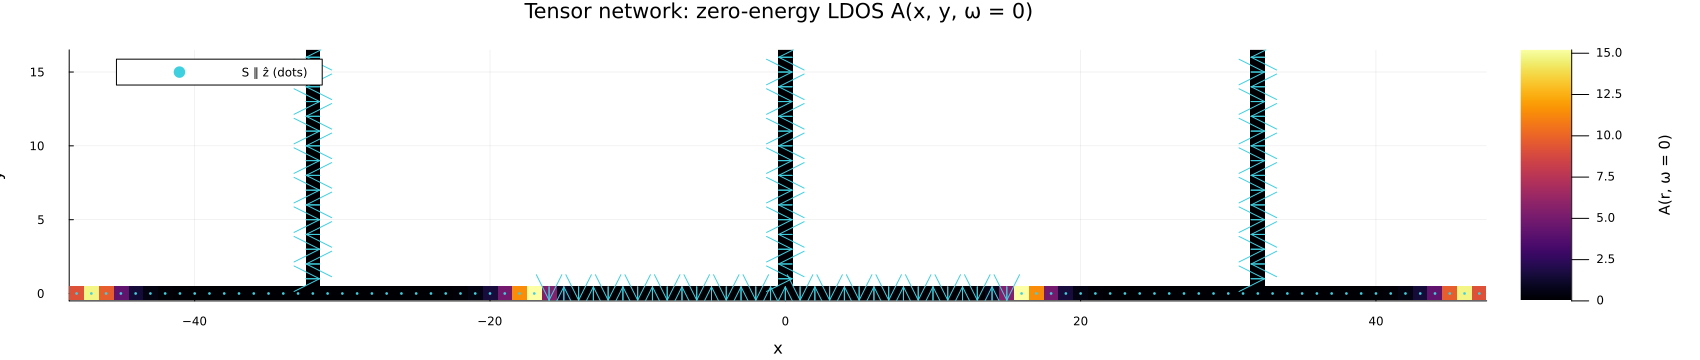

In [8]:
j0 = argmin(abs.(ωs))
xs_ = first.(xy); ys_ = last.(xy)
xg = minimum(xs_):maximum(xs_); yg = minimum(ys_):maximum(ys_)
grid = fill(NaN, length(yg), length(xg))
for (i, (x, y)) in enumerate(xy); grid[y - first(yg) + 1, x - first(xg) + 1] = A_tn[i, j0]; end
Sv = [array_spin(a, f0)(c, s, n) for (c, s, n) in sl]
Sx = getindex.(Sv, 1); Sy = getindex.(Sv, 2)
inpl = hypot.(Sx, Sy) .> 0.5
pl = heatmap(xg, yg, grid; c=:inferno, clims=(0, maximum(A_tn[:, j0])), aspect_ratio=:equal,
             xlims=(first(xg) - 0.5, last(xg) + 0.5), ylims=(first(yg) - 0.5, last(yg) + 0.5),
             xlabel="x", ylabel="y", colorbar_title="A(r, ω = 0)", background_color_inside=:white,
             title="Tensor network: zero-energy LDOS A(x, y, ω = 0)", size=(1700, 360), margin=5Plots.mm)
sc = 1 / 1.1
quiver!(pl, xs_[inpl] .- sc .* Sx[inpl] ./ 2, ys_[inpl] .- sc .* Sy[inpl] ./ 2;
        quiver=(sc .* Sx[inpl], sc .* Sy[inpl]), color="#3FD0E0", lw=1)
scatter!(pl, xs_[.!inpl], ys_[.!inpl]; ms=1.5, color="#3FD0E0", markerstrokewidth=0, label="S ∥ ẑ (dots)")
savefig(pl, joinpath(ROOT, "nb_tn_ldos.png")); pl

## 6. Gates followed by partial fusion: logical gate, ΔQ and δn(x, t)

`gate_and_fusion` runs exchange × 2 (Z: exchange_12, X: exchange_23, or no gate) and then the partial fusion of pair A in one evolution.
It returns the braid matrix and logical gate after one and two exchanges, the fusion ΔQ(t), and δn on the horizontal chain at
snapshots every 5 time units during the gate and every 1 during the fusion (the TDVP CSVs use the same times).
The Z and X (rot_Tx = 400) densities are written to `msh_gate_density_tn_{Z,X}.csv`.

In [9]:
# horizontal chain, left to right: per cell, left arm n = 15 … 0 then junction + right arm n = 0 … 15
hsites = [(c, s, n) for c in 1:a.ncell for (s, ns) in ((2, 15:-1:0), (1, 0:15)) for n in ns]
xh = [round(Int, array_pos(a, c, s, n)[1]) for (c, s, n) in hsites]

function gate_result(VT)
    M = real.(braid_matrix4(γ0, VT))
    Ũ, _ = logical_unitary(M)
    L = logical_even_block(Ũ)
    return (; M, Ũ, L, leak = leak4(γ0, VT), phase = rad2deg(mod(angle(L.UL[2, 2] / L.UL[1, 1]), 2π)), P01 = abs2(Ũ[4, 1]))
end

function gate_and_fusion(kind; rot_Tx=400.0, q=Fusion(), dt_gate=5.0, dt_fuse=1.0)
    if kind === :Z
        p = Exchange12(); fg = t -> f_array_braid(a, p, f0, t); T1 = duration(p); mov = [1]
    elseif kind === :X
        p = Exchange23(rot_T=rot_Tx); fg = t -> f_array_23(p, f0, t); T1 = duration(p); mov = [1, 2]
    else
        fg = t -> f0; T1 = 0.0; mov = [1]             # fusion only
    end
    Tg = 2T1; Tf = duration(q)
    B = MovingArrayH(a, t -> t < Tg ? fg(t < T1 ? t : t - T1) : f_fuse(q, f0, t - Tg), f0, mov)
    res = Dict{Symbol,Any}(:Tg => Tg)
    ts, Vs = [0.0], [V0]
    for (key, t0, t1, dts) in ((:one, 0.0, T1, dt_gate), (:two, T1, Tg, dt_gate), (:fusion, Tg, Tg + Tf, dt_fuse))
        t1 > t0 || continue
        tk, Vk = evolve_snap(B, Vs[end], t0, t1, dts)
        append!(ts, tk[2:end]); append!(Vs, Vk[2:end])
        key === :fusion || (res[key] = gate_result(Vs[end]))
    end
    HT = dense_H(B, Tg + Tf)
    ΔQad, Ep = ΔQ_adiabatic(HT)
    Ev, Uv = eigen(Hermitian(HT)); Zs = Uv[:, sortperm(abs.(Ev))[1:4]]
    fus = ts .>= Tg
    res[:fusion] = (; ΔQ = sum(ΔQ_modes(Vs[end])), ΔQpair = ΔQ_modes(Vs[end]), ΔQad, Ep,
                     leak = [1 - norm(Zs' * Vs[end][:, k])^2 for k in 1:2],
                     ts = ts[fus] .- Tg, ΔQt = [sum(ΔQ_modes(V)) for V in Vs[fus]])
    res[:ts] = ts
    res[:D] = reduce(vcat, [(w = δn_modes(V, a); [w[s, n+1, c] for (c, s, n) in hsites])' for V in Vs])   # (t, x)
    return res
end

function write_density(name, r)
    csv = joinpath(ROOT, "msh_gate_density_tn_$name.csv")
    open(csv, "w") do io
        println(io, "t,x,dn")
        for (i, t) in enumerate(r[:ts]), (j, x) in enumerate(xh)
            println(io, t, ",", x, ",", r[:D][i, j])
        end
    end
    println("wrote ", csv)
end

function density_figure(ts, D, Tg, gate; method="Tensor network")
    L = log10.(max.(abs.(D), 1e-16))
    p1 = heatmap(xh, ts, L; c=:inferno, clims=(-12, 0), xlabel="x (horizontal chain)", ylabel="t",
                 colorbar_title="log₁₀|n₁ − n₀|", title="$method: log₁₀|δn(x, t)|, full $gate protocol + fusion")
    hline!(p1, [Tg / 2, Tg]; color=:white, ls=:dash, lw=1, label="")
    vline!(p1, [-32, 0, 32]; color=:gray, ls=:dot, lw=0.8, label="")
    sel = ts .>= Tg; lim = maximum(abs, D[sel, :])
    p2 = heatmap(ts[sel] .- Tg, xh, permutedims(D[sel, :]); c=:RdBu, clims=(-lim, lim),
                 xlabel="t − T_gate (fusion)", ylabel="x (horizontal chain)", colorbar_title="δn = n₁ − n₀",
                 title=@sprintf("%s: δn(x, t) during the fusion after %s  (Σ_chain δn = %+.3f)", method, gate, sum(D[end, :])))
    hline!(p2, [-32, 0, 32]; color=:gray, ls=:dot, lw=0.8, label="")
    return plot(p1, p2; layout=(1, 2), size=(1700, 560), margin=6Plots.mm, titlefontsize=10)
end

density_figure (generic function with 1 method)

### Z gate: exchange_12 twice on junction 1, then partial fusion (and fusion with no gate)

Z (127 s): exchange_12 once: phase 90.7180°, leak [9.73e-7, 3.44e-15];  twice: phase 181.4359°, leak [2.0e-6, -6.66e-16], P(0→1) = 8.6e-27
Z + fusion   ΔQ = -0.477719 (A -0.477719, B +3.8e-08), adiabatic -0.476854, |E_A| = 0.0439, leak [3.69e-5, -2.22e-15]
fusion only  ΔQ = -0.477373 (A -0.477373, B +3.8e-08), adiabatic -0.476854, |E_A| = 0.0439, leak [3.78e-5, -5.33e-15]
wrote /tmp/claude-1030/-home-alaskowski/ff62b678-ce66-4c90-8c78-3a6344cea57c/scratchpad/run/msh_gate_density_tn_Z.csv


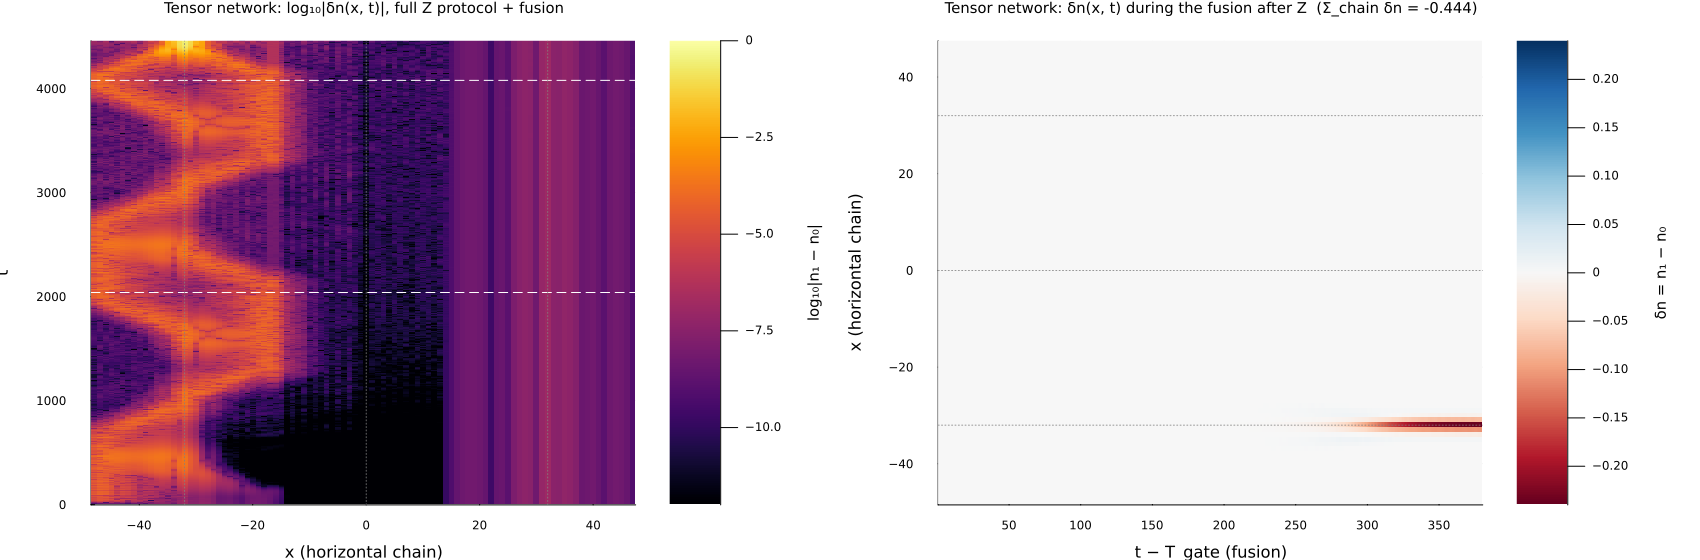

In [10]:
tZ = @elapsed rZ = gate_and_fusion(:Z)
rF = gate_and_fusion(:none)
@printf("Z (%.0f s): exchange_12 once: phase %.4f°, leak %s;  twice: phase %.4f°, leak %s, P(0→1) = %.1e\n",
        tZ, rZ[:one].phase, string(round.(rZ[:one].leak, sigdigits=3)), rZ[:two].phase,
        string(round.(rZ[:two].leak, sigdigits=3)), rZ[:two].P01)
for (lbl, r) in (("Z + fusion", rZ), ("fusion only", rF))
    f = r[:fusion]
    @printf("%-12s ΔQ = %+.6f (A %+.6f, B %+.1e), adiabatic %+.6f, |E_A| = %.4f, leak %s\n",
            lbl, f.ΔQ, f.ΔQpair..., f.ΔQad, f.Ep[2], string(round.(f.leak, sigdigits=3)))
end
write_density("Z", rZ)
pz = density_figure(rZ[:ts], rZ[:D], rZ[:Tg], "Z"); savefig(pz, joinpath(ROOT, "nb_tn_density_Z.png")); pz

### X gate: exchange_23 twice through junction 2 (rot_Tx = 100 and 400), then partial fusion

X rot_Tx = 100 (62 s): leak [0.108, 0.0928], θ = 179.245° about n̂ = [1.0, -0.0, -0.0], P(0→1) = 0.999957; fusion ΔQ = +0.443864 (A +0.411503, B +3.2e-02)
X rot_Tx = 400 (217 s): leak [3.42e-5, 3.49e-5], θ = 174.939° about n̂ = [1.0, -0.0, -0.0], P(0→1) = 0.998051; fusion ΔQ = +0.477005 (A +0.476113, B +8.9e-04)
wrote /tmp/claude-1030/-home-alaskowski/ff62b678-ce66-4c90-8c78-3a6344cea57c/scratchpad/run/msh_gate_density_tn_X.csv


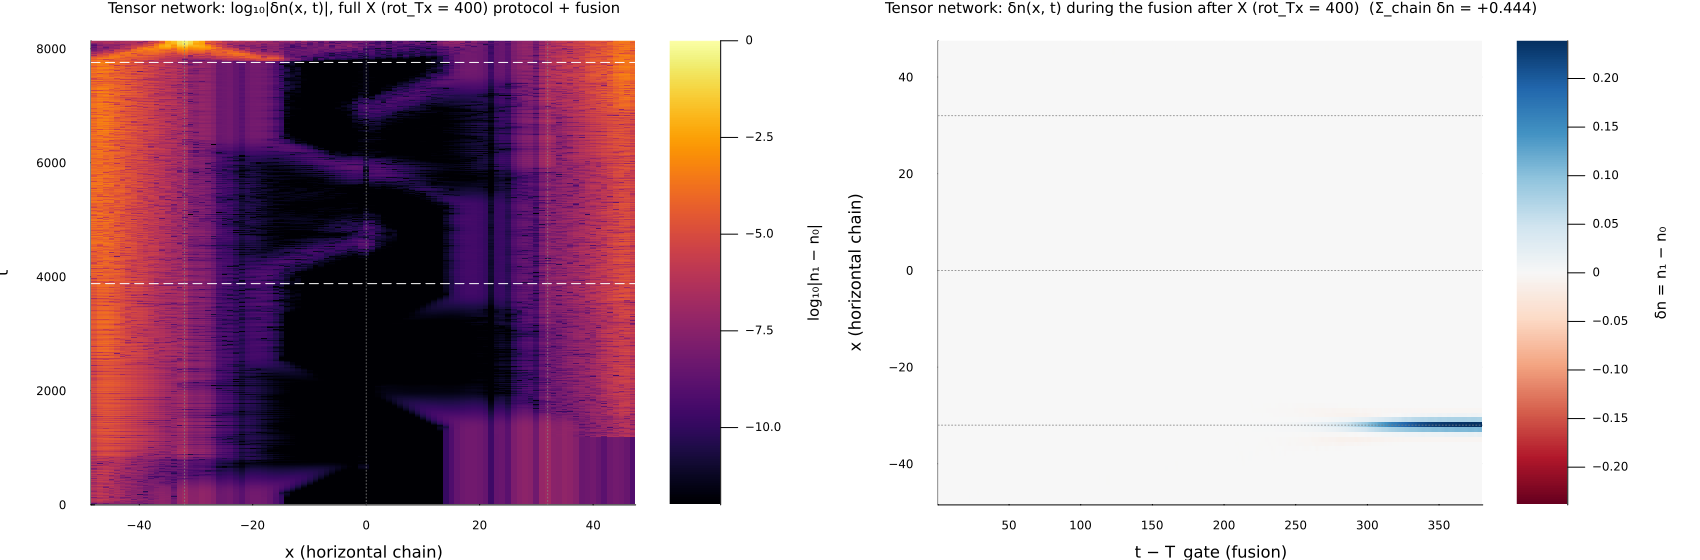

In [11]:
rX = Dict{Float64,Any}()
for rot in (100.0, 400.0)
    tX = @elapsed rX[rot] = gate_and_fusion(:X; rot_Tx=rot)
    r = rX[rot][:two]; f = rX[rot][:fusion]
    @printf("X rot_Tx = %.0f (%.0f s): leak %s, θ = %.3f° about n̂ = %s, P(0→1) = %.6f; fusion ΔQ = %+.6f (A %+.6f, B %+.1e)\n",
            rot, tX, string(round.(r.leak, sigdigits=3)), rad2deg(r.L.θ), string(round.(r.L.n̂, digits=4)),
            r.P01, f.ΔQ, f.ΔQpair...)
end
write_density("X", rX[400.0])
px = density_figure(rX[400.0][:ts], rX[400.0][:D], rX[400.0][:Tg], "X (rot_Tx = 400)")
savefig(px, joinpath(ROOT, "nb_tn_density_X.png")); px

## 7. MPS/TDVP evolution with the MPO

`msh_gate_density_tdvp.jl` evolved $\psi_A$ and $\psi_B$ as MPS through the whole protocol (gate + fusion) with the MPO $H(t)$ = `B(t)` of
`MovingArrayH`: 2-site TDVP (`TB.evolve_with_tdvp_timedep`), `reverse_step = true`, `maxdim = 64`, `tol = 1e-12`, `krylovdim = 30`, $dt = 0.1$,
same snapshot times as Section 6. One process per mode (~1.2 h for Z, ~2 h for X; χ saturates at 24):
```
julia msh_gate_density_tdvp.jl Z 1 &  julia msh_gate_density_tdvp.jl Z 2 &
julia msh_gate_density_tdvp.jl X 1 &  julia msh_gate_density_tdvp.jl X 2 &
```
The results, `msh_gate_density_tdvp_{Z,X}.csv`, are loaded here and compared with the exact evolution.
With `RUN_TDVP = true` the next cell repeats the TDVP over the first 400 time units of the Z gate inside the notebook.

In [12]:
if RUN_TDVP
    BZ = MovingArrayH(a, t -> f_array_braid(a, Exchange12(), f0, t), f0, [1])
    Twin = 400.0; nst = round(Int, Twin / 0.1)
    t_tdvp = @elapsed (sAB = [TB.evolve_with_tdvp_timedep(t -> BZ(t), mps_from_dense(V0[:, k], BZ.sites), nst, 0.1;
                                                         maxdim=64, cutoff=1e-20, tol=1e-12, krylovdim=30, reverse_step=true)
                              for k in 1:2])
    _, Vex = evolve_snap(BZ, V0, 0.0, Twin, Inf)
    VT = hcat((dense_vec(s[end], BZ.sites) for s in sAB)...)
    @printf("TDVP (%.0f s, χ ≤ %d): ‖ψ_TDVP(T) − ψ_exact(T)‖ = %.1e (A), %.1e (B);  max |δn_TDVP − δn_exact| = %.1e (max |δn| = %.1e)\n",
            t_tdvp, maximum(maxlinkdim, vcat(sAB...)), norm(VT[:, 1] - Vex[end][:, 1]), norm(VT[:, 2] - Vex[end][:, 2]),
            maximum(abs, δn_modes(VT, a) - δn_modes(Vex[end], a)), maximum(abs, δn_modes(Vex[end], a)))
end

Z: max |δn_TDVP − δn_exact| = 1.4e-06 (max |δn| = 0.240); during the gate 1.4e-06 (max |δn| = 4.6e-04);  Σ_chain δn(T): TDVP -0.444369, exact -0.444370


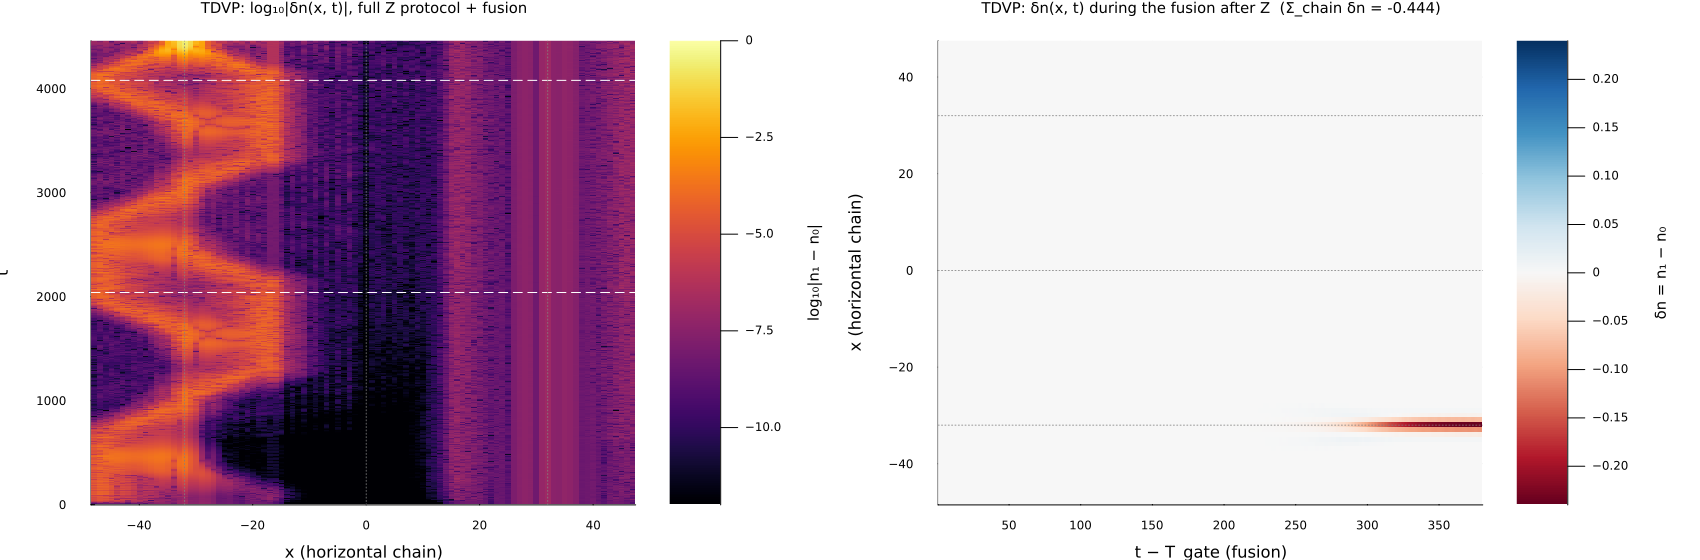

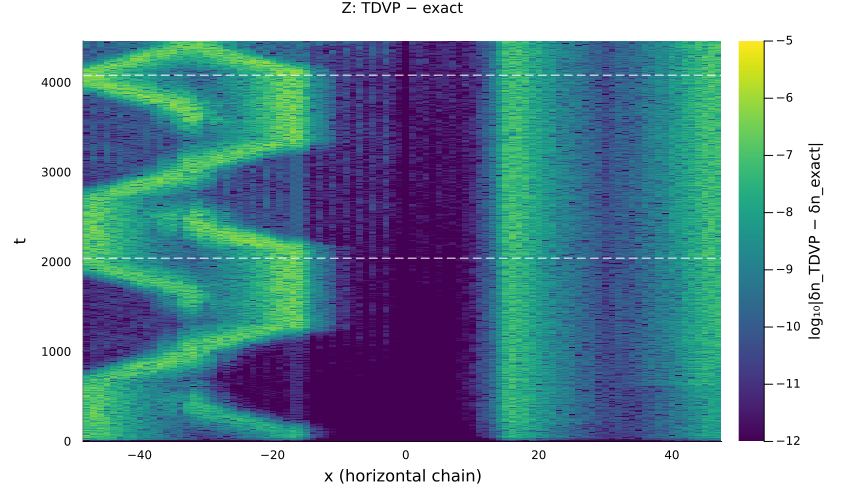

X: max |δn_TDVP − δn_exact| = 8.8e-07 (max |δn| = 0.239); during the gate 8.1e-07 (max |δn| = 7.7e-04);  Σ_chain δn(T): TDVP +0.444081, exact +0.444081


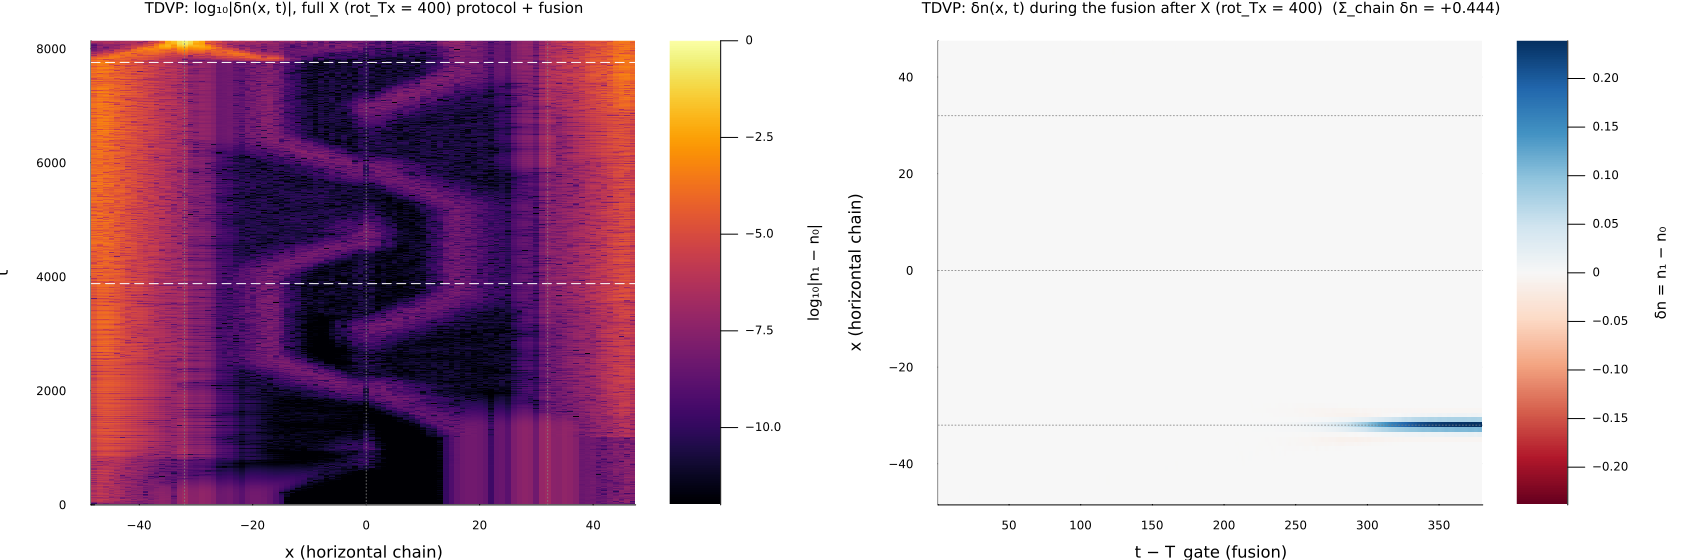

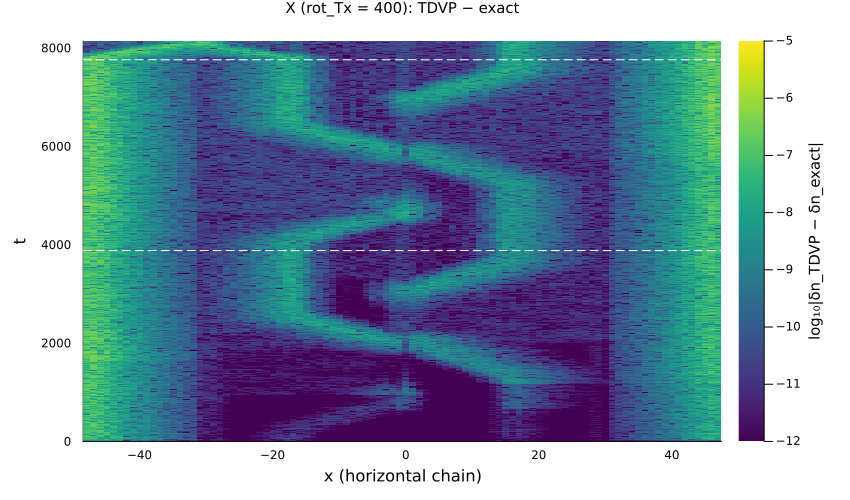

In [13]:
load_density(csv) = (d = readdlm(csv, ',', Float64; skipstart=1); ts = unique(d[:, 1]);
                     (ts, permutedims(reshape(d[:, 3], length(xh), length(ts)))))
for (name, r, gate) in (("Z", rZ, "Z"), ("X", rX[400.0], "X (rot_Tx = 400)"))
    csv = joinpath(ROOT, "msh_gate_density_tdvp_$name.csv")
    isfile(csv) || (println("no ", csv, "; run msh_gate_density_tdvp.jl first"); continue)
    tsT, DT = load_density(csv)
    ts, D, Tg = r[:ts], r[:D], r[:Tg]
    @assert tsT ≈ ts
    g = ts .<= Tg
    @printf("%s: max |δn_TDVP − δn_exact| = %.1e (max |δn| = %.3f); during the gate %.1e (max |δn| = %.1e);  Σ_chain δn(T): TDVP %+.6f, exact %+.6f\n",
            name, maximum(abs, DT - D), maximum(abs, D), maximum(abs, DT[g, :] - D[g, :]), maximum(abs, D[g, :]),
            sum(DT[end, :]), sum(D[end, :]))
    f = density_figure(tsT, DT, Tg, gate; method="TDVP")
    savefig(f, joinpath(ROOT, "nb_tdvp_density_$name.png")); display(f)
    pe = heatmap(xh, ts, log10.(max.(abs.(DT - D), 1e-16)); c=:viridis, clims=(-12, -5), xlabel="x (horizontal chain)",
                 ylabel="t", colorbar_title="log₁₀|δn_TDVP − δn_exact|", size=(850, 500), margin=5Plots.mm,
                 title="$gate: TDVP − exact", titlefontsize=10)
    hline!(pe, [Tg / 2, Tg]; color=:white, ls=:dash, lw=1, label="")
    display(pe)
end

## 8. Summary: Julia (this notebook) vs kwant V6

quantity                  Julia       kwant V6
S phase                  90.718         90.718
Z phase                 181.436        181.436
Z leak A             1.9962e-06          2e-06
ΔQ Z+fusion           -0.477719      -0.477719
ΔQ fusion only        -0.477373      -0.477373
ΔQ adiabatic          -0.476854      -0.476854
X100 leak A            0.108426       0.108426
X100 leak B            0.092757       0.092757
ΔQ X100+fusion         0.443864       0.443864
X400 θ                  174.939        174.939
X400 P(0→1)            0.998051       0.998051
X400 leak A         3.41647e-05       3.42e-05
ΔQ X400+fusion         0.477005       0.477005


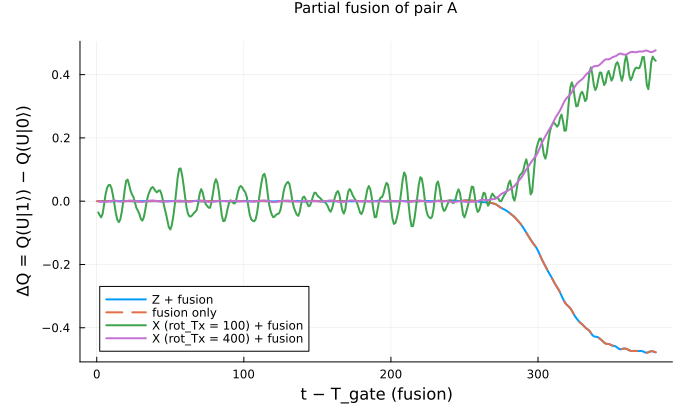

In [14]:
kwant = Dict("S phase" => 90.718, "Z phase" => 181.436, "Z leak A" => 2e-6, "ΔQ Z+fusion" => -0.477719,
             "ΔQ fusion only" => -0.477373, "ΔQ adiabatic" => -0.476854,
             "X100 leak A" => 0.1084264, "X100 leak B" => 0.092757, "ΔQ X100+fusion" => 0.443864,
             "X400 θ" => 174.9391, "X400 P(0→1)" => 0.998051, "X400 leak A" => 3.42e-5, "ΔQ X400+fusion" => 0.477005)
julia = Dict("S phase" => rZ[:one].phase, "Z phase" => rZ[:two].phase, "Z leak A" => rZ[:two].leak[1],
             "ΔQ Z+fusion" => rZ[:fusion].ΔQ, "ΔQ fusion only" => rF[:fusion].ΔQ, "ΔQ adiabatic" => rF[:fusion].ΔQad,
             "X100 leak A" => rX[100.0][:two].leak[1], "X100 leak B" => rX[100.0][:two].leak[2],
             "ΔQ X100+fusion" => rX[100.0][:fusion].ΔQ, "X400 θ" => rad2deg(rX[400.0][:two].L.θ),
             "X400 P(0→1)" => rX[400.0][:two].P01, "X400 leak A" => rX[400.0][:two].leak[1],
             "ΔQ X400+fusion" => rX[400.0][:fusion].ΔQ)
@printf("%-16s %14s %14s\n", "quantity", "Julia", "kwant V6")
for k in ["S phase", "Z phase", "Z leak A", "ΔQ Z+fusion", "ΔQ fusion only", "ΔQ adiabatic",
          "X100 leak A", "X100 leak B", "ΔQ X100+fusion", "X400 θ", "X400 P(0→1)", "X400 leak A", "ΔQ X400+fusion"]
    @printf("%-16s %14.6g %14.6g\n", k, julia[k], kwant[k])
end

pq = plot(xlabel="t − T_gate (fusion)", ylabel="ΔQ = Q(U|1⟩) − Q(U|0⟩)", legend=:bottomleft, size=(700, 420),
          title="Partial fusion of pair A", titlefontsize=10, margin=5Plots.mm)
for (lbl, r, ls) in (("Z + fusion", rZ, :solid), ("fusion only", rF, :dash),
                     ("X (rot_Tx = 100) + fusion", rX[100.0], :solid), ("X (rot_Tx = 400) + fusion", rX[400.0], :solid))
    plot!(pq, r[:fusion].ts, r[:fusion].ΔQt; lw=2, ls, label=lbl)
end
pq